# Phase 3 · Rhetorical Role Prediction

<div align="center">

## MODEL2 · Knowledge Distillation

**Mandatory distillation experiment**

`CS781 Capstone` &nbsp; · &nbsp; `Corporate Law + IT` &nbsp; · &nbsp; `Sentence classification`

</div>

---

### Experiment at a glance

| Item | Configuration |
|:--|:--|
| **Phase 1 backbone** | `model2(3).ipynb` |
| **Architecture** | RoPE, RMSNorm, QK normalization, GQA and a SiLU feed-forward network |
| **Representation size** | 512-dimensional hidden states |
| **Adaptation method** | Knowledge Distillation |
| **Checkpoint selection** | Development Macro-F1 |
| **Domains** | Corporate Law (CL) and Information Technology (IT) |

> **Objective**
>
> Loads an already full-finetuned Phase-3 teacher and trains a smaller student using hard labels and cached teacher predictions. The model predicts exactly one rhetorical-role label per sentence while preserving document order.

### Before you run

1. Attach your matching **already trained Phase-3 full-finetuning checkpoint**.
2. Set `TEACHER_CHECKPOINT_PATH` to its `.pt` file (including the classification head and `label_names`).
3. Attach the exact tokenizer used by that teacher. Set `TEACHER_TOKENIZER_PATH`, or `ASSET_DIR` to the directory containing `custom_bpe_scratch.json`.
4. If the checkpoint lacks input metadata, set `TEACHER_INPUT_CONFIG` from its original training notebook. The example is not automatically assumed.
5. Enable Kaggle internet and add the `HF` secret with access to the Phase-3 dataset.

**No teacher training occurs.** A missing/incompatible teacher stops with a clear error. A Phase-1 LM checkpoint, KD student, or unmerged LoRA/LORMA checkpoint is not accepted as a full-finetuned teacher.

### Notebook workflow

`Setup` → `Tokenizer` → `Backbone` → `Data` → `Load frozen teacher & cache logits` → `Student training & validation` → `Predictions`

---

**Run cells from top to bottom.** Training has not been executed in this environment, so no performance scores are claimed.




In [12]:
import json, os, random, math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
ASSET_DIR = Path('/kaggle/input/datasets/baihuwang07/phase1/')
MODEL_FAMILY = 'model2'
OUTPUT_DIR = Path('/kaggle/working/phase3_rr_model2_kd')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Attach the EXISTING full-finetuned Phase-3 teacher and its matching tokenizer.
TEACHER_CHECKPOINT_PATH = Path('/kaggle/input/datasets/baihuwang07/bestm2lora/best_rr_checkpoint.pt')
# None locates custom_bpe_scratch.json under ASSET_DIR; set an exact path if elsewhere.
TEACHER_TOKENIZER_PATH = None
# Old checkpoints may omit preprocessing metadata. In that case, explicitly fill
# this from the notebook used to train that teacher, for example:
# TEACHER_INPUT_CONFIG = {'max_length': 256, 'previous_context': True,
#                         'pooling': 'target_mean'}
# Supported pooling: 'target_mean' or 'target_mean_and_last_average'.
# Do NOT guess: whole-sequence pooling or different context construction needs
# the corresponding teacher implementation, not just a different checkpoint path.
TEACHER_INPUT_CONFIG = {'max_length': 256, 'previous_context': True,
                        'pooling': 'target_mean'}
POOLING = 'target_mean_and_last_average'

VOCAB_SIZE = 32000
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4
MODEL_CONTEXT_LENGTH = 2048
MAX_LENGTH = 256
BATCH_SIZE = 4
EPOCHS = 8
WEIGHT_DECAY = 0.01
DROPOUT = 0.15
GRAD_CLIP = 1.0
GRAD_ACCUM_STEPS = 4  # effective batch size = 16
WARMUP_RATIO = 0.1
PATIENCE = 3
USE_CLASS_WEIGHTS = True  # bounded inverse-square-root weights from train only
USE_GRAD_CHECKPOINTING = True
AMP_DTYPE = torch.bfloat16 if DEVICE.type == 'cuda' and torch.cuda.is_bf16_supported() else torch.float16
DOMAIN = 'both' 
USE_PREVIOUS_SENTENCE_CONTEXT = True

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# Authenticate with a Kaggle Secret named HF. Never paste a real token into a notebook.
def get_hf_token():
    token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if token:
        return token
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF")
    except Exception:
        token = None
    if not token:
        from getpass import getpass
        token = getpass("Hugging Face token (input hidden): ").strip()
    if not token:
        raise RuntimeError(
            "A Hugging Face token is required. In Kaggle, add a secret named 'HF' "
            "containing your token and enable access to secrets for this notebook."
        )
    return token

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
from huggingface_hub import hf_hub_download
print("Hugging Face authentication configured for", HF_DATASET_REPO)

def locate_asset(filename):
    root = Path(ASSET_DIR)
    if not root.exists():
        raise FileNotFoundError(f'Attach the matching Phase-1 asset dataset and set ASSET_DIR. Missing: {root}')
    hits = list(root.rglob(filename))
    if not hits:
        raise FileNotFoundError(f'{filename} not found below {root}')
    if len(hits) > 1:
        raise ValueError(f'Ambiguous asset {filename}: {hits}; set ASSET_DIR to one checkpoint directory.')
    return hits[0]

def fetch_json(path):
    """Download a Phase-3 JSON file from the private Hugging Face dataset repo."""
    try:
        local_path = hf_hub_download(
            repo_id=HF_DATASET_REPO,
            filename=path,
            repo_type="dataset",
            token=HF_TOKEN,
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not download {path} from {HF_DATASET_REPO}. Check that your Hugging Face "
            "token is valid, has read access to the repository, and that the HF secret is "
            "named exactly 'HF' in Kaggle. Also verify that the file path exists in the repo. "
            f"Original error: {exc}"
        ) from exc
    with open(local_path, "r", encoding="utf-8") as f:
        return json.load(f)

def records_from_payload(payload, labeled=True):
    if isinstance(payload, dict):
        if 'text' in payload and 'id' in payload:
            docs = [payload]
        else:
            docs = []
            for did, v in payload.items():
                if isinstance(v, dict):
                    r = dict(v)
                    r.setdefault('id', str(did))
                    docs.append(r)
                else:
                    docs.append({'id': str(did), 'text': v})
    elif isinstance(payload, list):
        docs = payload
    else:
        raise ValueError('Unsupported payload type ' + str(type(payload)))
    out = []
    seen_ids = set()
    for d in docs:
        did = str(d.get('id', d.get('document_id', d.get('doc_id', ''))))
        if not did or did in seen_ids:
            raise ValueError(f'Missing or duplicate document ID: {did!r}')
        seen_ids.add(did)
        ss = d.get('text', d.get('sentences', []))
        if isinstance(ss, str):
            ss = [ss]
        labs = d.get('labels', []) if labeled else None
        if labeled and (not isinstance(labs, list) or len(labs) != len(ss)):
            raise ValueError(f'{did}: label/sentence length mismatch')
        for i, s in enumerate(ss):
            out.append({'doc_id': did, 'sent_idx': i, 'sentence': str(s), 'label': labs[i] if labeled else None, 'sentences': ss})
    return out

def label_names_from_vocab(v):
    if isinstance(v, list):
        return list(map(str, v))
    if isinstance(v, dict):
        if all((isinstance(x, int) for x in v.values())):
            return [k for k, _ in sorted(v.items(), key=lambda kv: kv[1])]
        if all((str(k).isdigit() for k in v)):
            return [str(x) for k, x in sorted(v.items(), key=lambda kv: int(kv[0]))]
        return list(v.keys())
    raise ValueError('Unsupported label_vocab structure')

def context_text(r):
    """Human-readable context; only previous sentence plus the target are used."""
    ss = r['sentences']
    i = r['sent_idx']
    if not USE_PREVIOUS_SENTENCE_CONTEXT or i == 0:
        return ss[i]
    return 'Previous sentence: ' + ss[i - 1] + '\nTarget sentence: ' + ss[i]

class RRDataset(Dataset):
    """Sentence-level examples with an explicit mask for target-sentence tokens."""
    def __init__(self, records, tokenizer, label_to_id, labeled=True):
        self.records = records
        self.tokenizer = tokenizer
        self.label_to_id = label_to_id
        self.labeled = labeled
        self.encoded = {}

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        if i in self.encoded:
            return self.encoded[i]
        r = self.records[i]
        target_ids = self.tokenizer.encode(r["sentence"])
        if not target_ids:
            target_ids = [1]
        
        # Exactly matches your uploaded teacher notebook.
        target_ids = target_ids[-MAX_LENGTH:]
        remaining = max(0, MAX_LENGTH - len(target_ids))
        
        prefix_text = "Target sentence: "
        if USE_PREVIOUS_SENTENCE_CONTEXT and r["sent_idx"] > 0:
            prefix_text = (
                "Previous sentence: "
                + r["sentences"][r["sent_idx"] - 1]
                + "\nTarget sentence: "
            )
        
        prefix_ids = (
            self.tokenizer.encode(prefix_text)[-remaining:]
            if remaining > 0 else []
        )
        
        ids = prefix_ids + target_ids
        target_start = len(prefix_ids)
        target_mask = [False] * target_start + [True] * len(target_ids)
        x = {'input_ids': ids, 'target_mask': target_mask, 'record': r}
        if self.labeled:
            if r['label'] not in self.label_to_id:
                raise ValueError(f"Unknown label {r['label']!r} for document {r['doc_id']} sentence {r['sent_idx']}")
            x['label'] = self.label_to_id[r['label']]
        self.encoded[i] = x
        return x

def collate_rr(batch):
    n = max(len(x['input_ids']) for x in batch)
    ids = torch.zeros((len(batch), n), dtype=torch.long)
    mask = torch.zeros((len(batch), n), dtype=torch.bool)
    target_mask = torch.zeros((len(batch), n), dtype=torch.bool)
    for i, x in enumerate(batch):
        length = len(x['input_ids'])
        ids[i, :length] = torch.tensor(x['input_ids'], dtype=torch.long)
        mask[i, :length] = True
        target_mask[i, :length] = torch.tensor(x['target_mask'], dtype=torch.bool)
        if not target_mask[i].any():
            raise RuntimeError('Target token mask is empty; refusing to train on an invalid example.')
    labels = torch.tensor([x['label'] for x in batch], dtype=torch.long) if 'label' in batch[0] else None
    return ids, mask, target_mask, labels, [x['record'] for x in batch]

class SentenceClassifier(nn.Module):
    def __init__(self, backbone, hidden_size, num_labels):
        super().__init__()
        self.backbone = backbone
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, ids, mask, target_mask):
        h = self.backbone.forward_hidden(ids, attention_mask=mask)
        weights = target_mask.to(h.dtype).unsqueeze(-1)
        pooled = (h.float() * weights.float()).sum(dim=1) / weights.float().sum(dim=1).clamp_min(1.0)
        last = mask.long().sum(dim=1) - 1
        if POOLING == 'target_mean_and_last_average':
            pooled = 0.5 * (pooled + h[torch.arange(h.size(0), device=h.device), last].float())
        elif POOLING != 'target_mean':
            raise ValueError(f'Unsupported teacher pooling: {POOLING}')
        return self.classifier(self.dropout(pooled))

def evaluate(model, loader, nlabels):
    model.eval()
    ys, ps = [], []
    tot, n = 0.0, 0
    with torch.no_grad():
        for ids, mask, target_mask, y, _ in loader:
            ids, mask, target_mask, y = ids.to(DEVICE), mask.to(DEVICE), target_mask.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == 'cuda'):
                z = model(ids, mask, target_mask)
            tot += manual_cross_entropy(z, y, reduction='sum').item()
            n += y.numel()
            ys.extend(y.cpu().tolist())
            ps.extend(z.argmax(-1).cpu().tolist())
    labels = list(range(nlabels))
    return ({'loss': tot / max(n, 1),
             'macro_f1': f1_score(ys, ps, average='macro', labels=labels, zero_division=0),
             'macro_precision': precision_score(ys, ps, average='macro', labels=labels, zero_division=0),
             'macro_recall': recall_score(ys, ps, average='macro', labels=labels, zero_division=0)}, ys, ps)


# Basic tensor operations only for task losses; no fused attention/Transformer APIs.
def manual_log_softmax(x):
    x = x.float()
    x = x - x.amax(dim=-1, keepdim=True)
    return x - x.exp().sum(dim=-1, keepdim=True).log()

def manual_cross_entropy(logits, targets, weights=None, reduction='mean'):
    losses = -manual_log_softmax(logits).gather(-1, targets[:, None]).squeeze(-1)
    if weights is not None:
        losses = losses * weights[targets]
    return losses.sum() if reduction == 'sum' else losses.mean()

def run_config(model):
    return dict(model_family=MODEL_FAMILY, vocab_size=VOCAB_SIZE, hidden_size=N_EMBD,
                teacher_layers=N_LAYER, layers=len(model.backbone.layers),
                source_layer_ids=getattr(model.backbone, 'source_layer_ids', list(range(N_LAYER))),
                heads=N_HEAD, kv_heads=N_KV_HEAD, model_context=MODEL_CONTEXT_LENGTH,
                max_length=MAX_LENGTH, previous_context=USE_PREVIOUS_SENTENCE_CONTEXT,
                pooling=POOLING, dropout=DROPOUT, seed=SEED,
                kd_temperature=KD_TEMPERATURE, hard_label_weight=KD_ALPHA,
                gradient_accumulation=GRAD_ACCUM_STEPS, class_balance=USE_CLASS_WEIGHTS,
                tokenizer_file='custom_bpe_scratch.json', tokenizer_sha256=TOKENIZER_SHA256,
                teacher_checkpoint=str(TEACHER_CHECKPOINT_PATH))

def make_optimizer(model):
    groups = []
    for is_head, lr in [(False, LR_BACKBONE), (True, LR_HEAD)]:
        for decay in [False, True]:
            params = [p for n,p in model.named_parameters() if p.requires_grad
                      and n.startswith('classifier.') == is_head and (p.ndim >= 2) == decay]
            if params:
                groups.append({'params': params, 'lr': lr, 'weight_decay': WEIGHT_DECAY if decay else 0.0})
    return torch.optim.AdamW(groups)

def train_model(model, train_loader, dev_loader, label_names, optimizer, extra_loss=None,
                checkpoint_name='best_rr_checkpoint.pt'):
    if not len(train_loader) or not len(dev_loader):
        raise ValueError('Training and development splits must be non-empty.')
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda' and AMP_DTYPE == torch.float16)
    best, stale, hist = -1.0, 0, []
    ckpt_path = OUTPUT_DIR / checkpoint_name
    steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
    total_steps = EPOCHS * steps_per_epoch
    warmup_steps = max(1, round(WARMUP_RATIO * total_steps))
    base_lrs = [g['lr'] for g in optimizer.param_groups]
    step = 0
    for ep in range(1, EPOCHS + 1):
        model.train()
        running, seen = 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        for batch_idx, (ids, mask, target_mask, y, records) in enumerate(train_loader):
            ids, mask = ids.to(DEVICE), mask.to(DEVICE)
            target_mask, y = target_mask.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == 'cuda'):
                logits = model(ids, mask, target_mask)
                loss = manual_cross_entropy(logits, y, CLASS_WEIGHTS)
                if extra_loss is not None:
                    loss = extra_loss(loss, logits, records)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss at epoch {ep}')
            # Normalize by actual example count, including the last partial accumulation group.
            group_start = (batch_idx // GRAD_ACCUM_STEPS) * GRAD_ACCUM_STEPS
            group_examples = min(GRAD_ACCUM_STEPS * train_loader.batch_size,
                                 len(train_loader.dataset) - group_start * train_loader.batch_size)
            scaler.scale(loss * y.numel() / group_examples).backward()
            if (batch_idx + 1) % GRAD_ACCUM_STEPS == 0 or batch_idx + 1 == len(train_loader):
                scale = ((step + 1) / warmup_steps if step < warmup_steps else
                         0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / max(1, total_steps - warmup_steps))))
                for g, lr in zip(optimizer.param_groups, base_lrs):
                    g['lr'] = lr * scale
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                step += 1
            running += float(loss.detach()) * y.numel()
            seen += y.numel()
        met, _, _ = evaluate(model, dev_loader, len(label_names))
        hist.append({'epoch': ep, 'train_loss': running / seen, **met})
        print(f"epoch={ep} train_loss={running / seen:.4f} dev_macro_f1={met['macro_f1']:.4f}")
        if met['macro_f1'] > best:
            best, stale = met['macro_f1'], 0
            torch.save({'model_state_dict': {k: v.detach().cpu() for k,v in model.state_dict().items()},
                        'epoch': ep, 'metrics': met, 'label_names': label_names,
                        'config': run_config(model)}, ckpt_path)
        else:
            stale += 1
        if stale >= PATIENCE:
            print('Early stopping; restoring best development Macro-F1 checkpoint.')
            break
    ck = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    model.load_state_dict(ck['model_state_dict'], strict=True)
    del ck
    with open(OUTPUT_DIR / (Path(checkpoint_name).stem + '_history.json'), 'w') as f:
        json.dump(hist, f, indent=2)
    plt.figure(figsize=(7, 4))
    plt.plot([x['epoch'] for x in hist], [x['train_loss'] for x in hist], marker='o', label='train objective')
    plt.plot([x['epoch'] for x in hist], [x['loss'] for x in hist], marker='o', label='dev unweighted CE')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / (Path(checkpoint_name).stem + '_loss_curve.png'), dpi=150)
    plt.show()
    return model, hist, ckpt_path

def save_predictions(model, records, label_names, label_to_id, suffix):
    loader = DataLoader(RRDataset(records, tokenizer, label_to_id, False), batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=collate_rr)
    pred = {}
    model.eval()
    with torch.no_grad():
        for ids, mask, target_mask, _, rs in loader:
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == 'cuda'):
                ys = model(ids.to(DEVICE), mask.to(DEVICE), target_mask.to(DEVICE)).argmax(-1).cpu().tolist()
            for r, y in zip(rs, ys):
                pred.setdefault(r['doc_id'], {})[r['sent_idx']] = label_names[y]
    ordered = {}
    for r in records:
        if r['doc_id'] not in ordered:
            ordered[r['doc_id']] = [None] * len(r['sentences'])
        ordered[r['doc_id']][r['sent_idx']] = pred[r['doc_id']][r['sent_idx']]
    assert all(x is not None for vv in ordered.values() for x in vv), 'Prediction output has missing sentence labels.'
    p = OUTPUT_DIR / f'{suffix}_prediction.json'
    json.dump(ordered, open(p, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
    return p


Device: cuda
Hugging Face authentication configured for Exploration-Lab/CS-781-Capstone


## 1. Phase-1 custom byte-level BPE tokenizer

Exact tokenizer class extracted from the matching Phase-1 notebook.

In [13]:
import re
from collections import Counter, defaultdict

class CustomByteLevelBPE:

    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {}
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        self.pad_id = 0

    def train(self, texts, target_vocab_size):
        print('Aggregating byte sequence frequencies...')
        word_freqs = Counter()
        for text in texts:
            chunks = re.findall('\\S+|\\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode('utf-8')] += 1
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f'Unique byte sequences to process: {len(word_freqs):,}')
        splits = {word: list(word) for word in word_freqs}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j + 1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)
        num_merges = target_vocab_size - 256
        print(f'Starting {num_merges} merges...')
        for i in range(num_merges):
            if not pair_counts:
                break
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            words_to_update = list(pair_to_words.get(best_pair, []))
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                for j in range(len(split) - 1):
                    pair = (split[j], split[j + 1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j + 1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j + 1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
            self.next_id += 1
            if (i + 1) % 1000 == 0:
                print(f'Merge {i + 1}/{num_merges} completed.')
        print('BPE Training complete!')

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[ids[i], ids[i + 1]] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and (ids[i + 1] == pair[1]):
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        chunks = re.findall('\\S+|\\s+', text)
        final_ids = []
        for chunk in chunks:
            ids = list(chunk.encode('utf-8'))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float('inf')))
                if pair not in self.merges:
                    break
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
        return final_ids

    def decode(self, ids):
        b_text = b''.join((self.vocab[idx] for idx in ids if idx != self.pad_id))
        return b_text.decode('utf-8', errors='replace')

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f'{p[0]},{p[1]}': v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {'vocab_size': self.vocab_size, 'next_id': self.next_id, 'merges': serializable_merges, 'vocab': serializable_vocab}
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, 'r', encoding='utf-8') as f:
            data = json.load(f)
        self.vocab_size = data['vocab_size']
        self.next_id = data['next_id']
        self.merges = {tuple(map(int, k.split(','))): v for k, v in data['merges'].items()}
        self.vocab = {int(k): bytes(v) for k, v in data['vocab'].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

# Notes preserved from the original cell:
# Base vocabulary of all 256 individual bytes
# Reserved Special Tokens
# 1. Chunk texts to prevent massive contiguous memory blocks
# Split into words and whitespace blocks to keep sequence lengths small
# 2. Drop singletons to massively save RAM
# Initialize splits: word -> list of byte integers
# 3. Build fast inverted index
# Record the merge
# 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
# Remove old pairs associated with this word from global tracking
# Execute the merge on this word's internal list
# Add newly formed pairs back to global tracking
# Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents


## 2. Phase-1 model architecture

Exact custom model classes from the supplied notebook; only original model instantiation is omitted.

In [14]:
class ManualSiLU(nn.Module):
    def forward(self, x):
        return x * torch.sigmoid(x)

class ManualGELU(nn.Module):
    def forward(self, x):
        return (0.5 * x.float() * (1.0 + torch.erf(x.float() / math.sqrt(2.0)))).to(x.dtype)

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):

    def __init__(self, dim, eps=1e-06):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        norm = xf * torch.rsqrt(xf.square().mean(-1, keepdim=True) + self.eps)
        return (norm * self.weight.float()).to(x.dtype)


def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / theta ** (torch.arange(0, dim, 2)[:dim // 2].float() / dim)
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return (torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk))

class ManualTransformerAttention(nn.Module):

    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool=True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        k_transposed = k.transpose(-2, -1).contiguous()
        with torch.autocast(device_type=q.device.type, enabled=False):
            scores = torch.matmul(q.float(), k_transposed.float()) * self.scale
        if is_causal:
            query_pos = torch.arange(L_q, device=q.device) + (L_k - L_q)
            mask = (torch.arange(L_k, device=q.device)[None, :] <= query_pos[:, None]).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
        weights = (scores - scores.amax(dim=-1, keepdim=True)).exp()
        weights = weights / weights.sum(dim=-1, keepdim=True).clamp_min(1e-20)
        return torch.matmul(weights.to(v.dtype), v.contiguous())

class GroupedQueryAttention(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = (n_heads, n_kv_heads, dim // n_heads)
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)
        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        q, k = apply_rotary_emb(q, k, freqs_cis)
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1)
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)
        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        out = self.manual_attention(q=q.transpose(1, 2), k=k_rep.transpose(1, 2), v=v_rep.transpose(1, 2), is_causal=True, attention_mask=attention_mask)
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return (self.wo(out), new_kv_cache)

class CustomTransformerBlock(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        self.ffn = nn.Sequential(nn.Linear(dim, dim * 4, bias=False), ManualSiLU(), nn.Linear(dim * 4, dim, bias=False))

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out
        out = h + self.ffn(self.norm2(h))
        return (out, new_kv_cache)

class CustomLegalModel(nn.Module):

    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        self.register_buffer('freqs_cis', precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos:start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        h = self.tok_embeddings(tokens)
        new_caches = []
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)
        return (self.output(self.norm(h)), new_caches)

# Notes preserved from the original cell:
# ==========================================
# 4. Custom Architecture (RoPE, RMSNorm, GQA, QK-Norm, Sequential)
# ==========================================
# Apply padding mask for batched inference
# QK-Norm layers for stabilization
# Apply QK-Norm directly after linear projections
# class SwiGLU_FFN(nn.Module):
#     def __init__(self, dim, hidden_dim=None):
#         super().__init__()
#         if hidden_dim is None:
#             hidden_dim = int(8 * dim / 3)
#             hidden_dim = 256 * ((hidden_dim + 255) // 256)
#         self.w1 = nn.Linear(dim, hidden_dim, bias=False)
#         self.w2 = nn.Linear(hidden_dim, dim, bias=False)
#         self.w3 = nn.Linear(dim, hidden_dim, bias=False)
#     def forward(self, x):
#         return self.w2(F.silu(self.w1(x)) * self.w3(x))
# Restored separate norm layers for sequential architecture
# Standard Sequential FFN with SiLU (Swish) instead of GELU
# Sequential Residual Architecture
# ---------------------------------------------
# Re-instantiate the model 
# ---------------------------------------------


In [15]:
N_EMBD = 512
MODEL_CONTEXT_LENGTH = 2048
backbone = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

def _forward_hidden(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
    B, L = tokens.shape
    freqs_cis = torch.view_as_complex(self.freqs_cis[start_pos:start_pos + L].to(tokens.device))
    h = self.tok_embeddings(tokens)
    for layer in self.layers:
        if self.training and USE_GRAD_CHECKPOINTING and torch.is_grad_enabled():
            from torch.utils.checkpoint import checkpoint
            # Bind layer now: backward recomputation must not capture the final loop value.
            def block_forward(x, block=layer):
                return block(x, freqs_cis, kv_cache=None, attention_mask=attention_mask)[0]
            h = checkpoint(block_forward, h, use_reentrant=False)
        else:
            h, _ = layer(h, freqs_cis, kv_cache=None, attention_mask=attention_mask)
    return self.norm(h)
backbone.forward_hidden = _forward_hidden.__get__(backbone, CustomLegalModel)
def load_teacher_bundle(path, input_override=None):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Set TEACHER_CHECKPOINT_PATH to your full-finetuned Phase-3 checkpoint: {path}')
    # Use only your own trusted checkpoint. It must contain the classification head.
    bundle = torch.load(path, map_location='cpu', weights_only=False)
    if not isinstance(bundle, dict) or 'model_state_dict' not in bundle or 'label_names' not in bundle:
        raise ValueError('Expected a Phase-3 checkpoint with model_state_dict and label_names; a Phase-1 LM checkpoint is insufficient.')
    cfg = bundle.get('config', {})
    expected = dict(model_family=MODEL_FAMILY, vocab_size=VOCAB_SIZE, hidden_size=N_EMBD,
                    layers=N_LAYER, heads=N_HEAD, kv_heads=N_KV_HEAD, model_context=MODEL_CONTEXT_LENGTH)
    for key,value in expected.items():
        if key in cfg and cfg[key] != value:
            raise ValueError(f'Teacher {key}={cfg[key]!r}; notebook requires {value!r}')
    required = ('max_length', 'previous_context', 'pooling')
    settings = {k: cfg[k] for k in required if k in cfg}
    if input_override is not None:
        for k in required:
            if k in input_override:
                if k in settings and settings[k] != input_override[k]:
                    raise ValueError(f'TEACHER_INPUT_CONFIG conflicts with checkpoint metadata: {k}')
                settings[k] = input_override[k]
    missing = [k for k in required if k not in settings]
    if missing:
        raise ValueError('Teacher lacks preprocessing metadata: ' + ', '.join(missing) +
                         '. Set TEACHER_INPUT_CONFIG from the original teacher notebook before running.')
    if settings['pooling'] not in ('target_mean', 'target_mean_and_last_average'):
        raise ValueError('Unsupported teacher pooling. Use its original classifier/input implementation.')
    if not isinstance(settings['max_length'], int) or not 0 < settings['max_length'] <= MODEL_CONTEXT_LENGTH:
        raise ValueError('Invalid teacher max_length')
    if not isinstance(settings['previous_context'], bool):
        raise ValueError('previous_context must be a boolean')
    return bundle, settings

teacher_bundle, teacher_input = load_teacher_bundle(TEACHER_CHECKPOINT_PATH, TEACHER_INPUT_CONFIG)
MAX_LENGTH = teacher_input['max_length']
USE_PREVIOUS_SENTENCE_CONTEXT = teacher_input['previous_context']
POOLING = teacher_input['pooling']
print('Teacher input settings:', teacher_input)
# No Phase-1 checkpoint reload and no teacher fine-tuning: all weights come from the teacher.
tokenizer_path = Path(TEACHER_TOKENIZER_PATH) if TEACHER_TOKENIZER_PATH else locate_asset('custom_bpe_scratch.json')
tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(str(tokenizer_path))
assert max(tokenizer.vocab) < VOCAB_SIZE, 'Tokenizer IDs exceed embedding vocabulary.'
import hashlib
TOKENIZER_SHA256 = hashlib.sha256(tokenizer_path.read_bytes()).hexdigest()
saved_tokenizer_hash = teacher_bundle.get('config', {}).get('tokenizer_sha256')
if saved_tokenizer_hash and saved_tokenizer_hash != TOKENIZER_SHA256:
    raise ValueError('Tokenizer hash differs from the teacher checkpoint.')
if not saved_tokenizer_hash:
    print('Teacher has no tokenizer hash. You must supply the exact tokenizer used to train it; vocabulary size alone cannot verify identity.')


Teacher input settings: {'max_length': 256, 'previous_context': True, 'pooling': 'target_mean'}
Teacher has no tokenizer hash. You must supply the exact tokenizer used to train it; vocabulary size alone cannot verify identity.


## 3. Phase-3 data and sentence examples

Development Macro-F1 is used for model selection. Both domains are enabled by default.

In [16]:
data = {k: fetch_json(v) for k, v in {'CL_train': 'Phase_3_RR/Train/CL_train.json', 'IT_train': 'Phase_3_RR/Train/IT_train.json', 'CL_dev': 'Phase_3_RR/Train/CL_dev.json', 'IT_dev': 'Phase_3_RR/Train/IT_dev.json', 'label_vocab': 'Phase_3_RR/Train/label_vocab.json', 'CL_test': 'Phase_3_RR/Test/CL_test.json', 'IT_test': 'Phase_3_RR/Test/IT_test.json'}.items()}
label_names = label_names_from_vocab(data['label_vocab'])
label_to_id = {v: i for i, v in enumerate(label_names)}
keys = ['CL', 'IT'] if DOMAIN == 'both' else [DOMAIN]
train_records = sum((records_from_payload(data[k + '_train'], True) for k in keys), [])
dev_records = sum((records_from_payload(data[k + '_dev'], True) for k in keys), [])
test_records = sum((records_from_payload(data[k + '_test'], False) for k in keys), [])
for i, r in enumerate(train_records):
    r['train_index'] = i
train_loader = DataLoader(RRDataset(train_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_rr)
dev_loader = DataLoader(RRDataset(dev_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
print('Labels:', label_names)
print('Train/dev/test sentences:', len(train_records), len(dev_records), len(test_records))

assert train_records and dev_records and test_records
assert len(label_names) == len(set(label_names))
for domain in keys:
    train_ids = {r['doc_id'] for r in records_from_payload(data[domain + '_train'], True)}
    dev_ids = {r['doc_id'] for r in records_from_payload(data[domain + '_dev'], True)}
    test_ids = {r['doc_id'] for r in records_from_payload(data[domain + '_test'], False)}
    assert not (train_ids & dev_ids or train_ids & test_ids or dev_ids & test_ids), f'{domain}: split overlap'
counts = torch.bincount(torch.tensor([label_to_id[r['label']] for r in train_records]), minlength=len(label_names)).float()
print('Train label support:', dict(zip(label_names, counts.int().tolist())))
if (counts == 0).any(): print('WARNING: some official classes have no training examples.')
weights = (counts.sum() / (len(label_names) * counts.clamp_min(1))).sqrt().clamp(0.5, 3.0)
weights /= (weights * counts).sum() / counts.sum()
CLASS_WEIGHTS = weights.to(DEVICE) if USE_CLASS_WEIGHTS else None

for split in ['train', 'dev', 'test']:
    all_ids = []
    for domain in keys:
        rr = records_from_payload(data[domain + '_' + split], split != 'test')
        all_ids += list(dict.fromkeys(r['doc_id'] for r in rr))
    if len(all_ids) != len(set(all_ids)):
        raise ValueError(f'{split}: document IDs collide across domains; use separate domain runs.')


Labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
Train/dev/test sentences: 16845 2142 2197
Train label support: {'Fact': 4098, 'Issue': 107, 'ArgumentPetitioner': 1613, 'ArgumentRespondent': 1348, 'Statute': 1099, 'Dissent': 284, 'PrecedentReliedUpon': 1945, 'PrecedentNotReliedUpon': 569, 'PrecedentOverruled': 3, 'RulingByLowerCourt': 874, 'RatioOfTheDecision': 4301, 'RulingByPresentCourt': 307, 'None': 297}


## 04 · Knowledge Distillation

The method-specific implementation below is applied to this notebook's matching Phase 1 backbone.

In [17]:
METHOD = 'Knowledge Distillation'
LR_BACKBONE = 2e-5
LR_HEAD = 2e-4
KD_TEMPERATURE = 2.0
KD_ALPHA = 0.7  # hard-label fraction; tune using development data only

def kd_loss(hard, student_logits, teacher_logits):
    t = KD_TEMPERATURE
    log_p = manual_log_softmax(teacher_logits / t)
    log_q = manual_log_softmax(student_logits / t)
    soft = (log_p.exp() * (log_p - log_q)).sum(dim=-1).mean() * t * t
    return KD_ALPHA * hard + (1.0 - KD_ALPHA) * soft


In [18]:
# Load an already trained Phase-3 teacher. No teacher optimizer/training is created.
import copy, gc
STUDENT_N_LAYER = max(4, N_LAYER // 2)
assert STUDENT_N_LAYER < N_LAYER
if teacher_bundle['label_names'] != label_names:
    raise ValueError('Teacher label names/order differ from label_vocab.json. Align the original teacher label mapping explicitly.')
teacher = SentenceClassifier(backbone, N_EMBD, len(label_names))
# Strict loading rejects missing heads, smaller students, and unmerged LoRA/LORMA layouts.
# teacher.load_state_dict(teacher_bundle['model_state_dict'], strict=True)
# Merge your Model-2 LoRA teacher into ordinary linear weights.
# Settings verified from your uploaded teacher notebook:
TEACHER_LORA_RANK = 8
TEACHER_LORA_ALPHA = 16.0

state = dict(teacher_bundle["model_state_dict"])
merged_count = 0

for layer_idx in range(N_LAYER):
    for projection in ("wq", "wk", "wv", "wo"):
        prefix = f"backbone.layers.{layer_idx}.attn.{projection}"

        required = [
            prefix + ".base.weight",
            prefix + ".A",
            prefix + ".B",
        ]
        if not all(key in state for key in required):
            raise ValueError(f"Missing LoRA weights for {prefix}")

        W = state.pop(prefix + ".base.weight").float()
        A = state.pop(prefix + ".A").float()
        B = state.pop(prefix + ".B").float()

        assert A.shape == (TEACHER_LORA_RANK, W.shape[1])
        assert B.shape == (W.shape[0], TEACHER_LORA_RANK)

        # Original LoRA forward:
        # W*x + (alpha/rank)*B*A*x
        merged_weight = W + (
            TEACHER_LORA_ALPHA / TEACHER_LORA_RANK
        ) * (B @ A)

        if not torch.isfinite(merged_weight).all():
            raise ValueError(f"Non-finite merged weights: {prefix}")

        state[prefix + ".weight"] = merged_weight
        merged_count += 1

teacher.load_state_dict(state, strict=True)
del state

print(f"Loaded teacher after merging {merged_count} LoRA projections.")
# Expected: 60 projections for 15 layers.
teacher_path = Path(TEACHER_CHECKPOINT_PATH)
del teacher_bundle
teacher.to(DEVICE).eval()
for p in teacher.parameters(): p.requires_grad_(False)
teacher_metrics, _, _ = evaluate(teacher, dev_loader, len(label_names))
teacher_history = [{'source': str(teacher_path), **teacher_metrics}]
print('Loaded teacher development metrics:', teacher_metrics)

# Fixed inputs: cache teacher logits once, indexed independently of shuffled batches.
teacher_logits_cache = torch.empty(len(train_records), len(label_names), dtype=torch.float32)
cache_loader = DataLoader(train_loader.dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
with torch.no_grad():
    for ids, mask, target_mask, _, rows in cache_loader:
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == 'cuda'):
            z = teacher(ids.to(DEVICE), mask.to(DEVICE), target_mask.to(DEVICE))
        teacher_logits_cache[[r['train_index'] for r in rows]] = z.float().cpu()
assert torch.isfinite(teacher_logits_cache).all()
# Move teacher off GPU before copying, then retain only the selected blocks.
teacher.cpu()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()
source_layer_ids = [round(i * (N_LAYER - 1) / (STUDENT_N_LAYER - 1)) for i in range(STUDENT_N_LAYER)]
student_backbone = copy.deepcopy(teacher.backbone)
student_backbone.layers = nn.ModuleList([student_backbone.layers[i] for i in source_layer_ids])
student_backbone.source_layer_ids = source_layer_ids
student_backbone.forward_hidden = _forward_hidden.__get__(student_backbone, CustomLegalModel)
model = SentenceClassifier(student_backbone, N_EMBD, len(label_names))
model.classifier.load_state_dict(teacher.classifier.state_dict())
# CRITICAL: deep-copying a frozen teacher also copies requires_grad=False.
for p in model.parameters():
    p.requires_grad_(True)
assert all(p.requires_grad for p in model.backbone.parameters())
parameter_count = lambda m: sum(p.numel() for p in m.parameters())
compression = {'teacher_parameters': parameter_count(teacher), 'student_parameters': parameter_count(model),
               'teacher_dev': teacher_history, 'source_layer_ids': source_layer_ids}
assert compression['student_parameters'] < compression['teacher_parameters']
print('Teacher/student parameters:', compression['teacher_parameters'], compression['student_parameters'])
with open(OUTPUT_DIR / 'distillation_summary.json', 'w') as f: json.dump(compression, f, indent=2)
del teacher, backbone, cache_loader
# teacher's CPU checkpoint remains on disk; only student resides on GPU during KD.
gc.collect()
model.to(DEVICE)
optimizer = make_optimizer(model)
def extra_loss(hard, logits, records):
    t_logits = teacher_logits_cache[[r['train_index'] for r in records]].to(logits.device)
    return kd_loss(hard, logits, t_logits)


Loaded teacher after merging 60 LoRA projections.
Loaded teacher development metrics: {'loss': 2.163142614716831, 'macro_f1': 0.2707802303153527, 'macro_precision': 0.30712968553772274, 'macro_recall': 0.28620516005899427}
Teacher/student parameters: 59671821 36588813


## 5. Train and evaluate on development data

epoch=1 train_loss=1.8756 dev_macro_f1=0.2260
epoch=2 train_loss=1.3269 dev_macro_f1=0.2441
epoch=3 train_loss=1.1139 dev_macro_f1=0.2735
epoch=4 train_loss=0.9667 dev_macro_f1=0.2874
epoch=5 train_loss=0.8466 dev_macro_f1=0.2601
epoch=6 train_loss=0.7484 dev_macro_f1=0.2700
epoch=7 train_loss=0.6799 dev_macro_f1=0.2764
Early stopping; restoring best development Macro-F1 checkpoint.


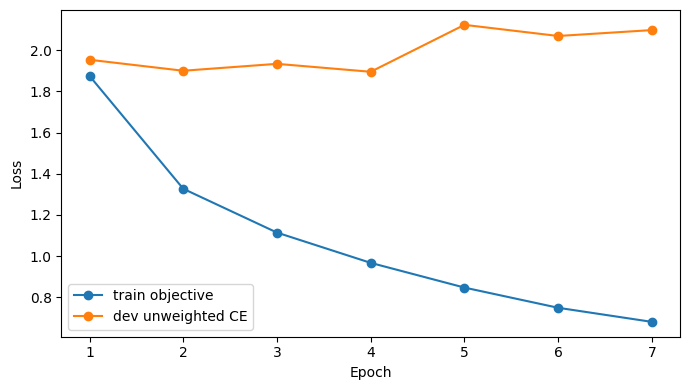

In [19]:
model, history, best_path = train_model(model, train_loader, dev_loader, label_names, optimizer, extra_loss=extra_loss)


Development metrics: {
  "loss": 1.8957299316177156,
  "macro_f1": 0.2874431012720015,
  "macro_precision": 0.3278845462912695,
  "macro_recall": 0.2823117823449683
}
                        precision    recall  f1-score   support

                  Fact       0.52      0.61      0.56       444
                 Issue       0.60      0.20      0.30        15
    ArgumentPetitioner       0.37      0.27      0.31       400
    ArgumentRespondent       0.41      0.31      0.35       272
               Statute       0.62      0.75      0.68       120
               Dissent       0.00      0.00      0.00         0
   PrecedentReliedUpon       0.32      0.34      0.33       254
PrecedentNotReliedUpon       0.21      0.24      0.22        50
    PrecedentOverruled       0.00      0.00      0.00         0
    RulingByLowerCourt       0.32      0.08      0.13       102
    RatioOfTheDecision       0.35      0.46      0.40       403
  RulingByPresentCourt       0.27      0.27      0.27        49


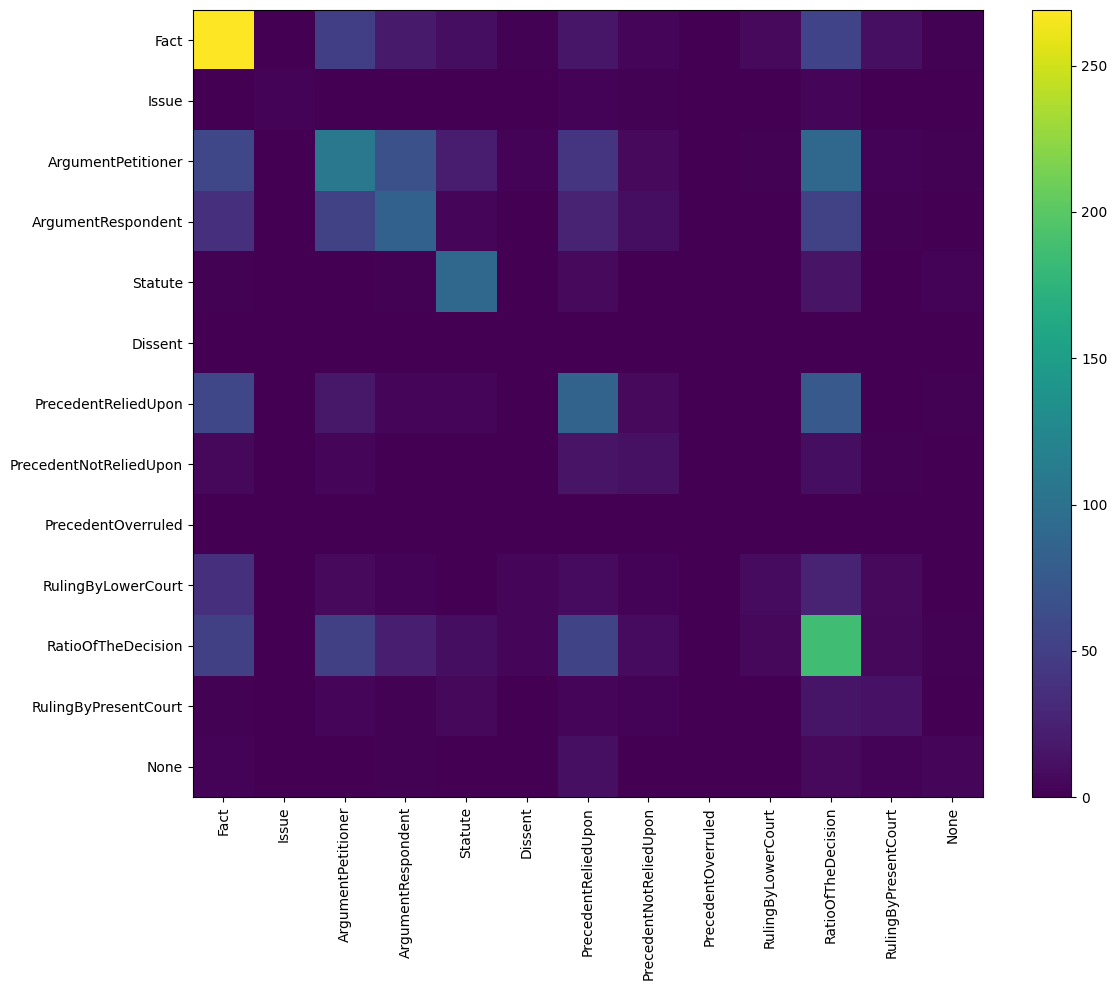

CL development metrics: {
  "loss": 1.87431038140398,
  "macro_f1": 0.2383236347502575,
  "macro_precision": 0.2465554348002118,
  "macro_recall": 0.2584890137835713
}
IT development metrics: {
  "loss": 1.9358126288005237,
  "macro_f1": 0.28280637658384467,
  "macro_precision": 0.3262408721568408,
  "macro_recall": 0.2723131623773548
}


In [20]:
metrics, gold, pred = evaluate(model, dev_loader, len(label_names))
print('Development metrics:', json.dumps(metrics, indent=2))
print(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
with open(OUTPUT_DIR / 'dev_report.txt', 'w', encoding='utf-8') as f:
    f.write(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
cm = confusion_matrix(gold, pred, labels=list(range(len(label_names))))
plt.figure(figsize=(12, 10))
plt.imshow(cm, aspect='auto')
plt.xticks(range(len(label_names)), label_names, rotation=90)
plt.yticks(range(len(label_names)), label_names)
plt.colorbar()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'dev_confusion_matrix.png', dpi=150)
plt.show()


# Domain-specific diagnostics (checkpoint selection still uses the combined dev set).
for domain_name, domain_rows in [('CL', data['CL_dev']), ('IT', data['IT_dev'])]:
    domain_records = records_from_payload(domain_rows, True)
    domain_loader = DataLoader(RRDataset(domain_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
    domain_metrics, domain_gold, domain_pred = evaluate(model, domain_loader, len(label_names))
    print(f'{domain_name} development metrics:', json.dumps(domain_metrics, indent=2))
    with open(OUTPUT_DIR / f'{domain_name.lower()}_dev_report.txt', 'w', encoding='utf-8') as f:
        f.write(classification_report(domain_gold, domain_pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))


## 6. Generate test prediction JSON

Output maps each document ID to ordered official label strings, one per sentence.

In [21]:
# Submit the student, not the teacher. Preserve exact document IDs and sentence order.
import zipfile, shutil
pred_path = save_predictions(model, test_records, label_names, label_to_id, MODEL_FAMILY + '_knowledge_distillation')
submission_path = OUTPUT_DIR / 'prediction.json'
with open(pred_path) as f: predictions = json.load(f)
expected = {}
for domain in keys:
    payload = data[domain + '_test']
    if isinstance(payload, list): docs = payload
    elif 'id' in payload and 'text' in payload: docs = [payload]
    else: docs = [dict(v, id=k) if isinstance(v, dict) else {'id': k, 'text': v} for k,v in payload.items()]
    for doc in docs:
        did = str(doc.get('id', doc.get('document_id', doc.get('doc_id', ''))))
        sentences = doc.get('text', doc.get('sentences', []))
        if isinstance(sentences, str): sentences = [sentences]
        if did in expected: raise ValueError(f'Duplicate test document: {did}')
        expected[did] = len(sentences)
        if not sentences: predictions[did] = []
assert set(predictions) == set(expected)
assert all(len(predictions[k]) == n for k,n in expected.items())
assert all(label in label_to_id for labels in predictions.values() for label in labels)
with open(submission_path, 'w', encoding='utf-8') as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(OUTPUT_DIR / 'submission.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(submission_path, arcname='prediction.json')
shutil.copy2(tokenizer_path, OUTPUT_DIR / 'custom_bpe_scratch.json')
print('Student predictions:', submission_path)
print('Submission ZIP:', OUTPUT_DIR / 'submission.zip')
print('Student checkpoint:', best_path)


Student predictions: /kaggle/working/phase3_rr_model2_kd/prediction.json
Submission ZIP: /kaggle/working/phase3_rr_model2_kd/submission.zip
Student checkpoint: /kaggle/working/phase3_rr_model2_kd/best_rr_checkpoint.pt


## Audit notes and limits

- Fixed the undefined context flag and explicitly unfroze every student parameter.
- Teacher and student both derive from this model's Phase-1 weights. Student keeps fewer trained blocks and copies the teacher head. Model 4 retains each selected block's original FFN type.
- Manual GQA, score multiplication, masks, softmax, RoPE, RMSNorm, activation functions, cross-entropy and KL. No SDPA, FlashAttention, MultiheadAttention, built-in Transformer or external pretrained model. Basic PyTorch tensor/layer operations, autograd and AdamW remain in use.
- Train-only bounded class weights, effective batch size 16, warm-up/cosine learning rate, and early stopping by official-label development Macro-F1. These are starting choices, not measured optimal hyperparameters.
- Teacher logits are cached for deterministic training inputs; no teacher forward pass is needed during student training. Gradient checkpointing reduces activation memory.
- The checkpoint saves the student layer map and input settings. To reload Model 4, construct the original full layer layout, select `source_layer_ids`, attach the sentence head, and strictly load the student state; constructing an ordinary alternating seven-layer model may have different FFN shapes.
- Only previous sentence context is used. Overlong targets keep their beginning and ending. The target representation averages its token mean and final-token state.
- Test labels are never used. Development data select checkpoints; test predictions preserve input order.
- Full training has not been run here. High F1 is not guaranteed; check the teacher's and student's Macro-F1 and per-class reports after running on Kaggle.
- Two KD notebooks do not alone satisfy all course experiments: the document additionally requires all four Phase-1 architectures, at least three adaptation techniques, and compulsory LORMA.

### Existing teacher reuse
- Teacher training is skipped entirely. The supplied full-finetuned Phase-3 weights are loaded strictly and evaluated once before their training-set logits are cached.
- Student initialization still retains seven teacher blocks and copies its classifier. All student weights are unfrozen; the teacher stays frozen.
- Checkpoint metadata controls max length, previous-sentence context and pooling. Missing metadata requires explicit settings from the teacher notebook. These options assume the same target masking, context serialization and truncation code; use the original pipeline if it differs.
- A tokenizer hash is checked when provided. Older checkpoints cannot prove tokenizer identity, so attach the teacher's exact tokenizer.
